In [6]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import scipy.stats as stats

# Параметри Варіанта 3 (Одеса)
np.random.seed(42)
city = "Одеса"
mean_temp = 11.5
amplitude = 13.0
hum_base = 73.0

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    
    if temp < 8:
        opal_days = 30       # опалювальний період триває весь місяць
    elif temp < 12:
        opal_days = 15       # опалювальний період триває частину місяця
    else:
        opal_days = 0        # опалення не потрібне

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city, 
        "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)
print("Набір даних heating успішно створено:")
print(heating)

Набір даних heating успішно створено:
    місто  місяць  температура  вологість  опалювальні_дні  \
0   Одеса       1         -1.0       72.3               30   
1   Одеса       2          1.8       71.8               30   
2   Одеса       3          6.6       76.8               30   
3   Одеса       4         12.0       70.7                0   
4   Одеса       5         18.2       63.4                0   
5   Одеса       6         22.2       67.9                0   
6   Одеса       7         23.6       65.9                0   
7   Одеса       8         22.5       73.3                0   
8   Одеса       9         17.5       73.6                0   
9   Одеса      10         11.9       70.0               15   
10  Одеса      11          4.4       82.3               30   
11  Одеса      12         -0.8       77.1               30   

    витрати_на_опалення  
0                 337.1  
1                 298.7  
2                 254.8  
3                 127.0  
4                  48.0  

In [7]:
# Підготовка даних для моделі з двома предикторами (температура, вологість)
X1 = sm.add_constant(heating[["температура", "вологість"]])
y = heating["витрати_на_опалення"]

model1 = sm.OLS(y, X1).fit()
print(model1.summary())

r2_m1 = model1.rsquared
adj_r2_m1 = model1.rsquared_adj
print(f"\nМодель 1: R² = {r2_m1:.4f}, Adjusted R² = {adj_r2_m1:.4f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.966
Model:                             OLS   Adj. R-squared:                  0.958
Method:                  Least Squares   F-statistic:                     126.2
Date:                 Sun, 11 Oct 2026   Prob (F-statistic):           2.61e-07
Time:                         14:59:53   Log-Likelihood:                -53.943
No. Observations:                   12   AIC:                             113.9
Df Residuals:                        9   BIC:                             115.3
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         213.8133    139.184      1

In [8]:
print("Значення VIF для моделі з двома предикторами:")
for i, col in enumerate(X1.columns):
    if col == "const":
        continue
    vif_value = variance_inflation_factor(X1.values, i)
    print(f"{col}: {vif_value:.2f}")

Значення VIF для моделі з двома предикторами:
температура: 1.56
вологість: 1.56


In [9]:
# Додаємо третій предиктор: опалювальні_дні
X2 = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
model2 = sm.OLS(y, X2).fit()
print(model2.summary())

print("--- Порівняння моделей ---")
print(f"Модель 1 (2 предиктори): R² = {model1.rsquared:.4f} | Adj. R² = {model1.rsquared_adj:.4f}")
print(f"Модель 2 (3 предиктори): R² = {model2.rsquared:.4f} | Adj. R² = {model2.rsquared_adj:.4f}")

# VIF для трипредикторної моделі
print("\nVIF для трипредикторної моделі:")
for i, col in enumerate(X2.columns):
    if col == "const":
        continue
    print(f"{col}: {variance_inflation_factor(X2.values, i):.2f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.989
Model:                             OLS   Adj. R-squared:                  0.985
Method:                  Least Squares   F-statistic:                     246.5
Date:                 Sun, 11 Oct 2026   Prob (F-statistic):           3.22e-08
Time:                         14:59:58   Log-Likelihood:                -46.933
No. Observations:                   12   AIC:                             101.9
Df Residuals:                        8   BIC:                             103.8
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             239.8118     8

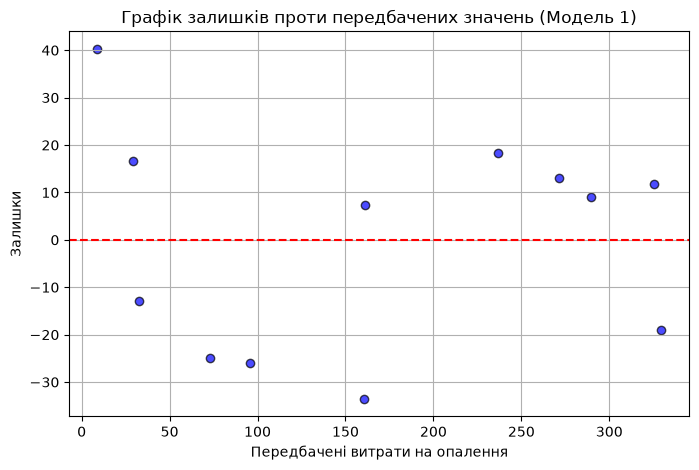

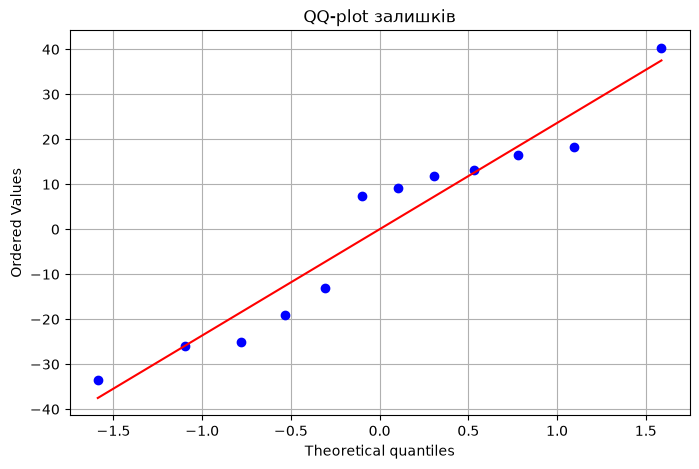

Критерій Шапіро-Вілка: статистика = 0.9285, p-value = 0.3646


In [10]:
fitted = model1.fittedvalues
residuals = model1.resid

# 1. Графік залишків проти передбачених значень
plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, color='blue', edgecolor='k', alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Передбачені витрати на опалення")
plt.ylabel("Залишки")
plt.title("Графік залишків проти передбачених значень (Модель 1)")
plt.grid(True)
plt.show()

# 2. QQ-plot та критерій Шапіро-Вілка
fig, ax = plt.subplots(figsize=(8, 5))
stats.probplot(residuals, dist="norm", plot=ax)
ax.set_title("QQ-plot залишків")
plt.grid(True)
plt.show()

shapiro_stat, shapiro_pvalue = stats.shapiro(residuals)
print(f"Критерій Шапіро-Вілка: статистика = {shapiro_stat:.4f}, p-value = {shapiro_pvalue:.4f}")

In [11]:
# Проста регресія лише за температурою
X_simple = sm.add_constant(heating[["температура"]])
model_simple = sm.OLS(y, X_simple).fit()

print(f"Проста регресія (тільки температура): R² = {model_simple.rsquared:.4f}")
print(f"Множинна регресія (температура + вологість): Adjusted R² = {model1.rsquared_adj:.4f}")

Проста регресія (тільки температура): R² = 0.9634
Множинна регресія (температура + вологість): Adjusted R² = 0.9579


## Відповіді на контрольні запитання

* **Чому `sm.add_constant()` обов'язковий крок перед `sm.OLS()`?**
Він додає до матриці предикторів стовпчик з одиницями, що дозволяє моделі обчислити вільний член (перетин з віссю ординат, `const`). Якщо його пропустити, регресійна пряма/площина проходитиме чітко через початок координат (знехтувавши вільним членом), що призведе до зміщення оцінок коефіцієнтів та спотворення результатів.
* **У чому коефіцієнт множинної регресії відрізняється від коефіцієнта простої регресії?**
У простій регресії коефіцієнт показує загальний зв'язок між єдиним предиктором і відгуком (включно з опосередкованим впливом інших факторів). У множинній регресії коефіцієнт інтерпретується **"за інших рівних умов"** (ceteris paribus) — він відокремлює чистий вплив цього предиктора, контролюючи (фіксуючи) значення всіх інших включених у модель змінних.
* **Чому звичайний $R^2$ не може зменшитись при додаванні нового предиктора?**
Додавання будь-якого додаткового стовпця даних до моделі МНК збільшує або залишає незмінною пояснену суму квадратів (ESS), оскільки мінімізація залишкової суми квадратів адаптується до нової змінної. Оскільки звичайний $R^2$ — це відношення ESS до TSS, він математично не може впасти. Саме тому використовується скоригований $R^2$ (`Adj. R²`), який вводить штраф за кожен новий параметр (ступінь свободи).
* **Що означає $VIF \approx 1$ і $VIF > 10$?**
$VIF \approx 1$ означає повну відсутність мультиколінеарності (предиктор абсолютно незалежний від інших). $VIF > 10$ вказує на критичну мультиколінеарність (сильний лінійний зв'язок між предикторами), що робить оцінки коефіцієнтів нестабільними та ненадійними. На практиці це вирішується вилученням однієї з колінеарних змінних, об'єднанням їх у комбінований індекс або застосуванням регуляризації (наприклад, Ridge-регресії).